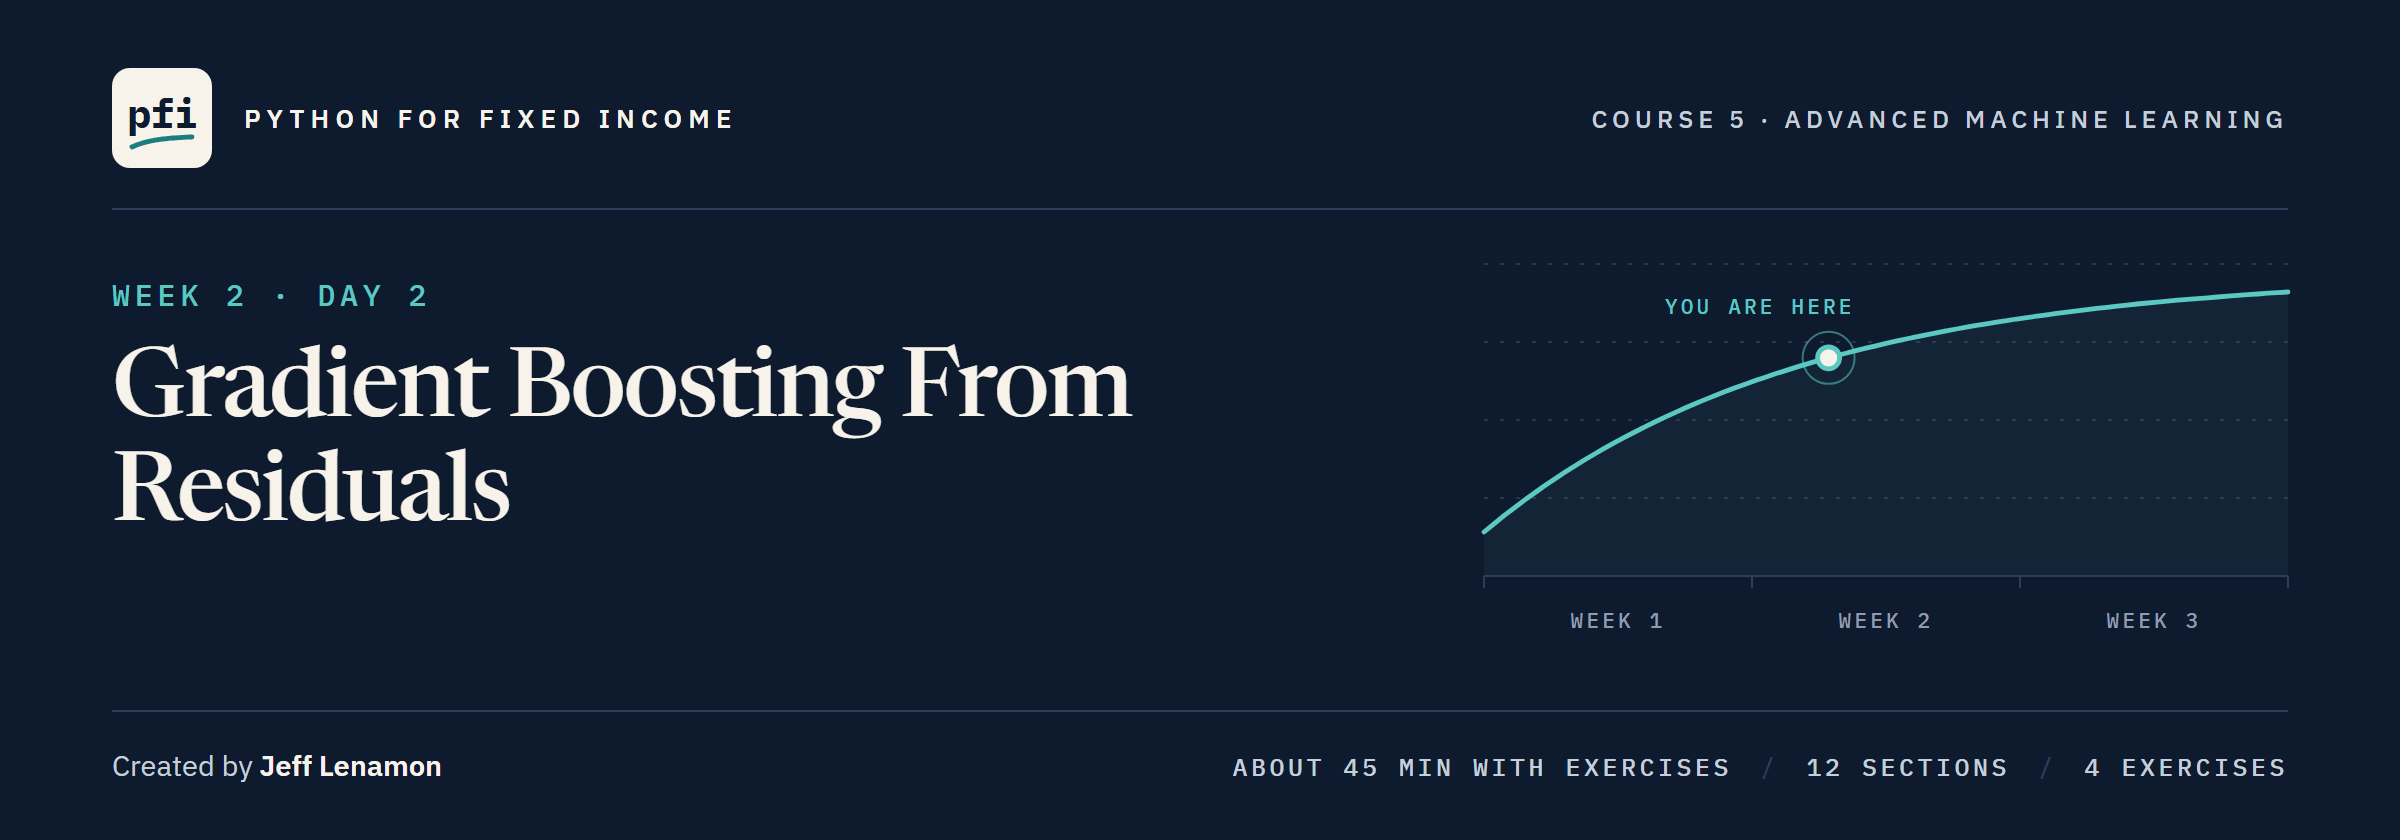

# Gradient Boosting From Residuals

Week 2, Day 2. Start every bond at the average spread, fit small trees one after another to what is still missed, rebuild scikit-learn's gradient boosting by hand, and see where it beats Course 4's line.

**Data:** `benchmark.csv` and `ratings.csv`, 821 bonds of invented issuers: **synthetic**, made for this course by `tools/make_holdings.py`. No real issuer, price, or spread.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week2/day2/07_gradient_boosting_from_residuals.ipynb)

# Problem Statement

## Business Context

Course 4's Day 5 left a least squares model of log OAS that misses a held-out training bond by 41.7 bp without coupon, 37.2 with it.
Day 5 averaged trees grown side by side on the same bonds; Day 6 grew small trees one after another on the card file.
The desk asks whether trees grown in sequence, each fitted to what the others still miss, describe the bonds better on the same five folds, and what goes on inside.
The bonds and issuers are invented for this course, and a fitted spread describes them, never a fair value or a view on a bond.

## Objectives

Fit gradient boosting and score it on five folds in bp, then rebuild it by hand from residuals and match the library.
Read the rounds, the learning rate and the depth from held-out curves, compare boosting with least squares and Day 5's forest without and with coupon, and find where a gain comes from.

## Data Dictionary

`benchmark.csv`, one row per bond:

1. `cusip`: the bond's identifier
2. `issuer` and `ticker`: the issuer's name and short code
3. `sector`: one of 10 industry sectors
4. `rating`: credit rating, AAA to CCC
5. `coupon`: annual coupon, percent of par
6. `maturity` and `as_of_date`: dates; years to maturity is built from them
7. `oas`: option-adjusted spread, bp; **the target is its log**
8. `duration`: modified duration, years
9. `amount_outstanding`: face value outstanding, dollars

`ratings.csv` adds `score` (1 for AAA up to 18 for CCC) and `grade`.

## Your Route Through Day 2

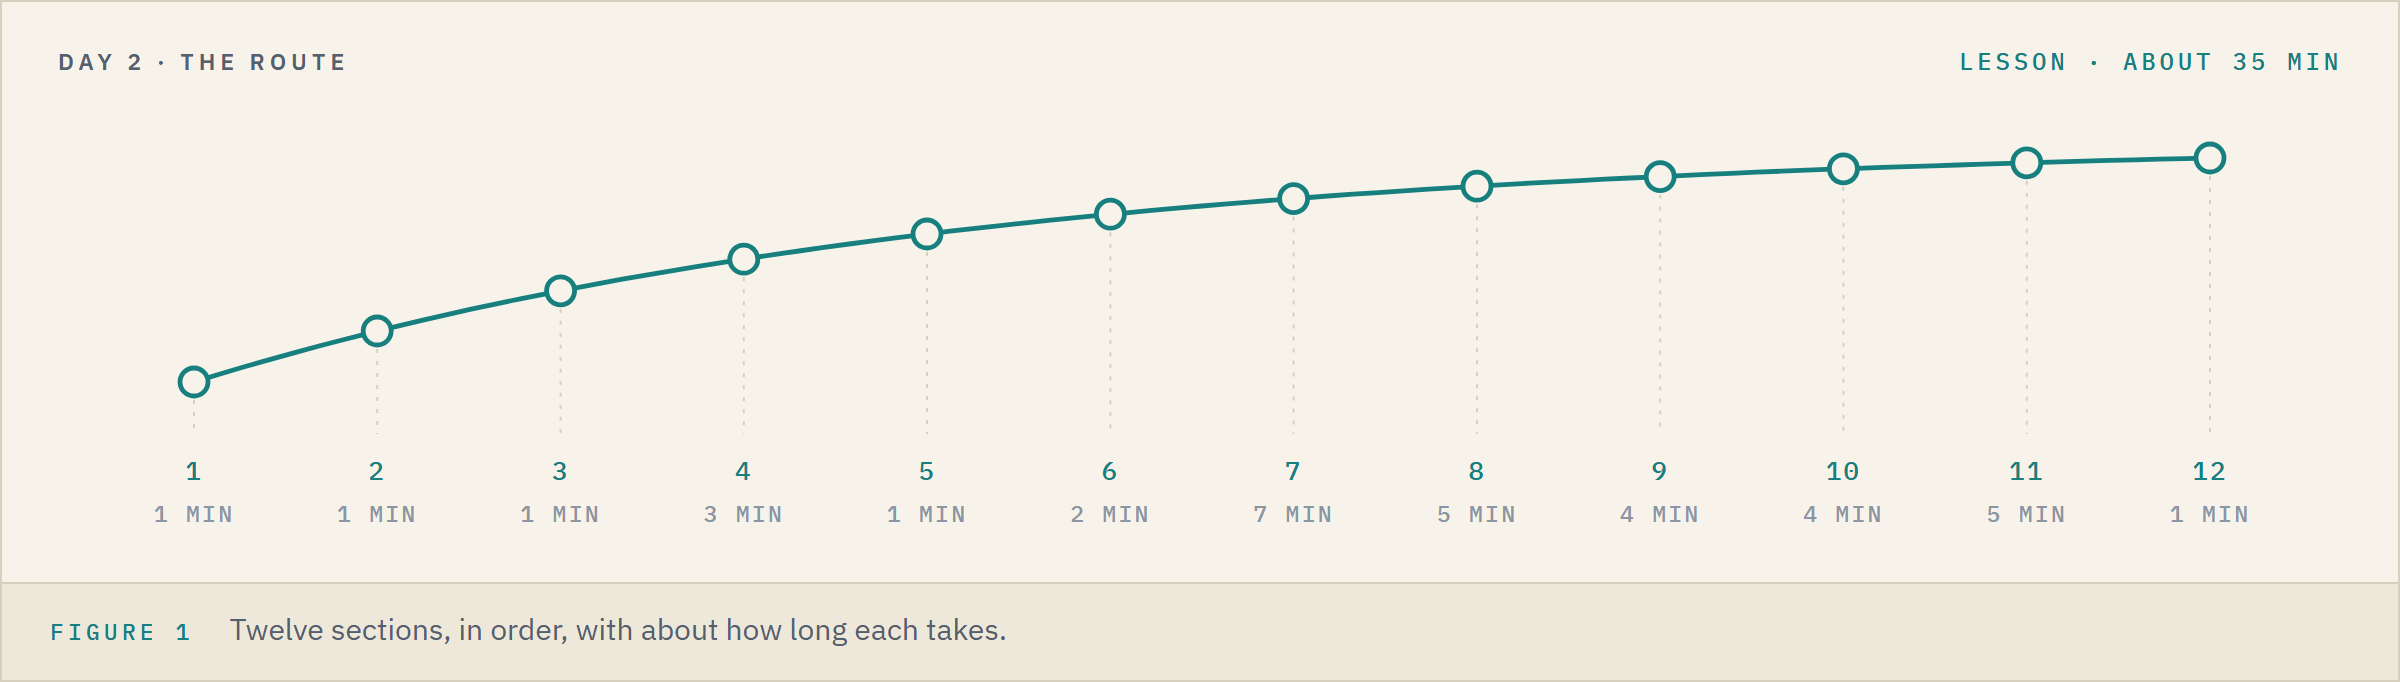

<table align="left">
<tr><th align="left"></th><th align="left">Section</th><th align="left">About</th></tr>
<tr><td align="left">1</td><td align="left">Setting Up</td><td align="left">1 min</td></tr>
<tr><td align="left">2</td><td align="left">Loading the Data</td><td align="left">1 min</td></tr>
<tr><td align="left">3</td><td align="left">Data Overview</td><td align="left">1 min</td></tr>
<tr><td align="left">4</td><td align="left">Exploratory Data Analysis</td><td align="left">3 min</td></tr>
<tr><td align="left">5</td><td align="left">Data Preparation for Modeling</td><td align="left">1 min</td></tr>
<tr><td align="left">6</td><td align="left">Model Building</td><td align="left">2 min</td></tr>
<tr><td align="left">7</td><td align="left">Inside the Model, Round by Round</td><td align="left">7 min</td></tr>
<tr><td align="left">8</td><td align="left">Watching the Rounds</td><td align="left">5 min</td></tr>
<tr><td align="left">9</td><td align="left">Rounds and the Learning Rate</td><td align="left">4 min</td></tr>
<tr><td align="left">10</td><td align="left">How Deep Each Tree</td><td align="left">4 min</td></tr>
<tr><td align="left">11</td><td align="left">Model Performance Comparison</td><td align="left">5 min</td></tr>
<tr><td align="left">12</td><td align="left">Insights and Conclusion</td><td align="left">1 min</td></tr>
</table>
<br clear="left">

**Time.** About 35 minutes for the lesson, then about 12 for the four exercises.

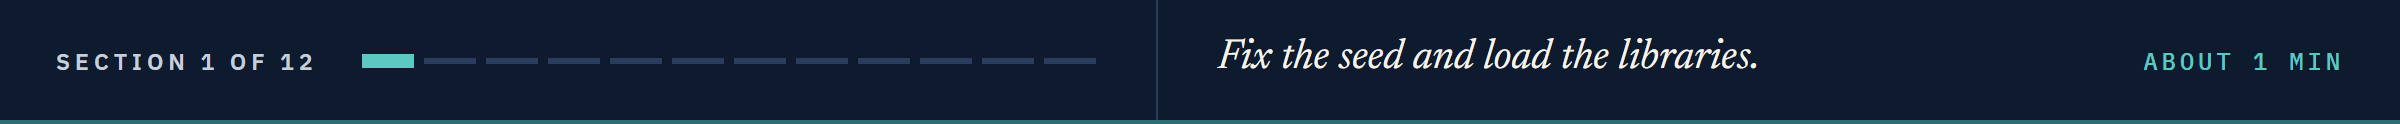

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and a slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# to split the bonds, fold the training bonds, and score on the folds
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_validate, cross_val_predict

# Course 4's line: its pipeline steps and least squares
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression

# trees, gradient boosting, and Day 5's forest
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor, HistGradientBoostingRegressor, RandomForestRegressor

# to measure misses in bp
from sklearn.metrics import mean_absolute_error, make_scorer

# one look for every chart, and three decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:,.3f}".format)

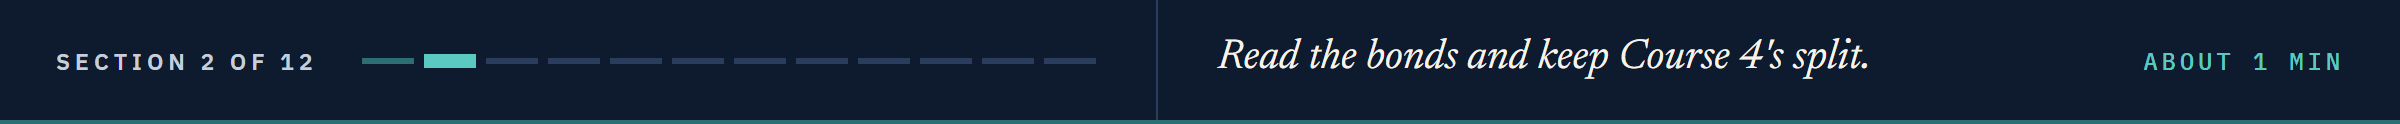

# Loading the Data

## Reading the Bonds and Building Three Columns

In [3]:
# the 821 bonds, and the table that turns each rating into a score and a grade
bonds = pd.read_csv(DATA + "benchmark.csv")
ratings = pd.read_csv(DATA + "ratings.csv")
data = bonds.merge(ratings[["rating", "score", "grade"]], on="rating")
rating_order = list(ratings["rating"])

# years to maturity, the amount in billions, and the target: the log of OAS (Course 4's Day 4)
data["years_to_maturity"] = (pd.to_datetime(data["maturity"]) - pd.to_datetime(data["as_of_date"])).dt.days / 365.25
data["amount_bn"] = data["amount_outstanding"] / 1e9
data["log_oas"] = np.log(data["oas"])

## Splitting the Bonds First

In [4]:
# Course 4's split, with the seed: the same 615 training and 206 test bonds
train, test = train_test_split(data, test_size=0.25, random_state=SEED)
y = train["log_oas"]
print("Training bonds:", len(train), " Test bonds:", len(test))

Training bonds: 615  Test bonds: 206


**The 206 test bonds were Course 4's; Course 5 never scores them. Everything below lives inside the 615.**

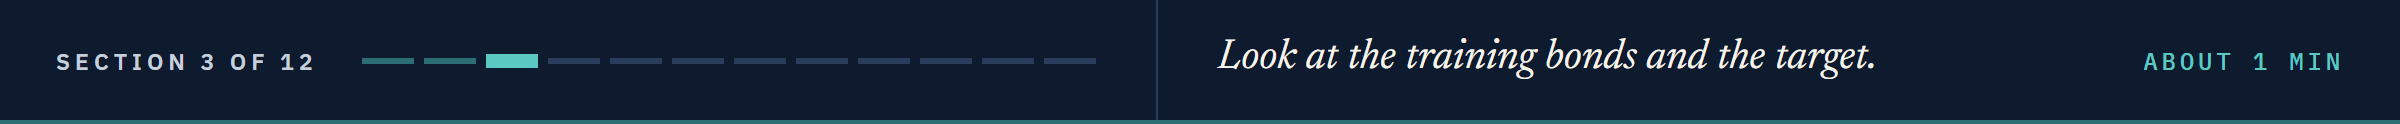

# Data Overview

## The Training Bonds

In [5]:
# the columns today's models read, and the target
train[["issuer", "rating", "score", "sector", "years_to_maturity", "duration", "amount_bn", "coupon", "log_oas"]].head()

,issuer,rating,score,sector,years_to_maturity,duration,amount_bn,coupon,log_oas
712,Elvellix Wireless,A+,5,Telecom,4.567,4.130,0.950,3.125,3.892
181,Heskorin Aerospace,A+,5,Industrials,19.803,13.456,1.600,3.250,4.078
778,Plevundra Finance,AA,3,Financials,2.538,2.371,1.150,3.250,3.091
716,Plevazor Energy,BBB-,10,Energy,3.422,3.040,2.300,6.000,5.380
636,Groventor Bancorp,BBB+,8,Financials,19.264,11.478,2.250,5.500,4.852


## The Target

In [6]:
# OAS in bp: its mean, its median and its widest bond, then the mean of its log, back in bp
print("Mean OAS:", round(train["oas"].mean(), 1), "bp  Median:", train["oas"].median(), "bp  Widest:", train["oas"].max(), "bp")
print("Mean log OAS:", round(y.mean(), 4), " exp of it:", round(np.exp(y.mean()), 1), "bp")

Mean OAS: 180.7 bp  Median: 123.0 bp  Widest: 2074 bp
Mean log OAS: 4.8776  exp of it: 131.3 bp


A long right tail pulls the mean above the median, so the target is the log, as in Course 4.

The mean of the log, turned back into bp, sits between the median and the mean.

**Familiar bonds and a familiar target: what we need is Course 4's best line to beat.**

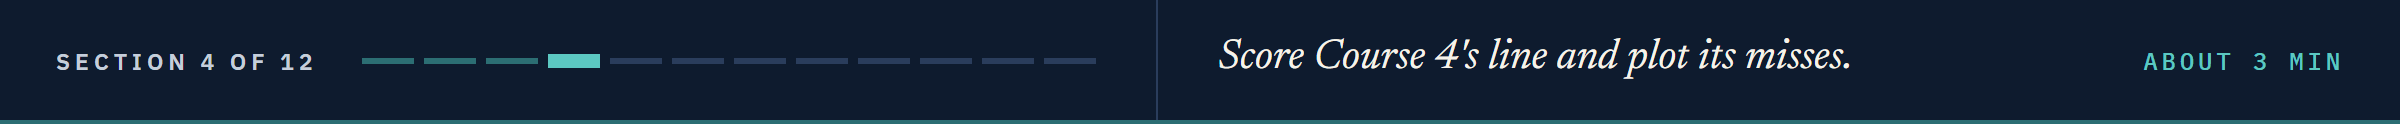

# Exploratory Data Analysis

## Course 4's Folds and Its Miss in bp

Course 4's Day 5 folded the training bonds five ways and measured every miss in bp.

In [7]:
# five folds of the training bonds, shuffled with the seed
folds = KFold(n_splits=5, shuffle=True, random_state=SEED)

# a miss in bp, both logs turned back through exp first, and the scorer that hands it to cross-validation
def mae_bp(y_log, fitted_log):
    return mean_absolute_error(np.exp(y_log), np.exp(fitted_log))

bp_scorer = make_scorer(mae_bp, greater_is_better=False)

## What Course 4's Line Leaves Behind

In [8]:
# Course 4's Day 5 line: rating and sector as indicator columns, the numbers scaled, then least squares
sectors = sorted(data["sector"].unique())
NO_COUPON = ["years_to_maturity", "duration", "amount_bn"]
def make_line(numbers):
    prep = ColumnTransformer([("categories", OneHotEncoder(categories=[rating_order, sectors], drop=["A", "Consumer"],
                                                           sparse_output=False), ["rating", "sector"]),
                              ("numbers", StandardScaler(), numbers)])
    return Pipeline([("prep", prep), ("model", LinearRegression())])

In [9]:
# the line without coupon: MAE in bp on each held-out fold, and the mean
line_folds = -cross_val_score(make_line(NO_COUPON), train, y, cv=folds, scoring=bp_scorer, n_jobs=1)
print("Folds:", line_folds.round(1), " Mean:", round(line_folds.mean(), 2), "bp")

Folds: [30.1 36.2 61.8 39.3 41.2]  Mean: 41.72 bp


Q. Does anything in the line's misses follow years to maturity?

In [10]:
# each training bond's fitted log OAS from the fold that held it out, and its miss
line_fitted = cross_val_predict(make_line(NO_COUPON), train, y, cv=folds, n_jobs=1)
line_miss = y - line_fitted

# the mean miss by maturity bucket
buckets = pd.cut(train["years_to_maturity"], [0, 2, 4, 6, 8, 10, 12, 20, 30])
line_miss.groupby(buckets, observed=False).agg(["size", "mean"])

,size,mean
years_to_maturity,,
"(0, 2]",74,-0.064
"(2, 4]",78,-0.017
"(4, 6]",93,-0.058
"(6, 8]",81,0.018
"(8, 10]",108,0.061
"(10, 12]",84,0.058
"(12, 20]",34,0.074
"(20, 30]",63,-0.081


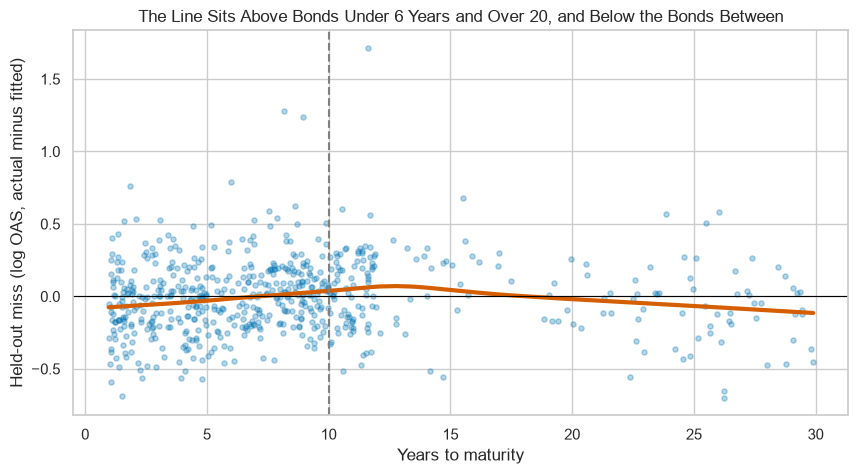

In [11]:
# the held-out misses against years to maturity, with a lowess curve, the recipe's 10-year cap dashed
sns.regplot(x=train["years_to_maturity"], y=line_miss, lowess=True, scatter_kws={"alpha": 0.3, "s": 14},
            line_kws={"color": "C3", "linewidth": 3})
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(10, color="gray", linestyle="--")
plt.xlabel("Years to maturity")
plt.ylabel("Held-out miss (log OAS, actual minus fitted)")
plt.title("The Line Sits Above Bonds Under 6 Years and Over 20, and Below the Bonds Between")
plt.show()

The mean miss is negative up to 6 years and beyond 20, and positive between, most of all from 8 to 20 years: an arch.

A straight line gives every year of maturity the same slope, so it cannot follow an arch.

**A straight line in years cannot bend at 10. Next, a model that finds its own bends.**

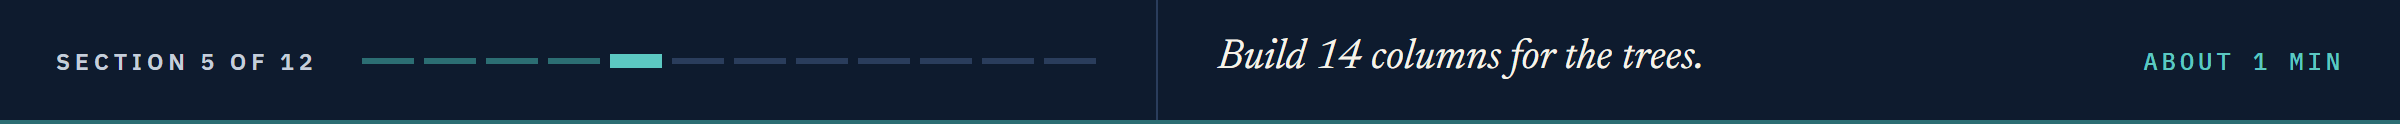

# Data Preparation for Modeling

## Features for Trees

In [12]:
# four numbers as they stand, and one 0.0 or 1.0 column per sector
X = pd.concat([train[["score", "years_to_maturity", "duration", "amount_bn"]], pd.get_dummies(train["sector"], dtype=float)], axis=1)
print(X.shape)
list(X.columns)

(615, 14)


['score',
 'years_to_maturity',
 'duration',
 'amount_bn',
 'Consumer',
 'Energy',
 'Financials',
 'Health Care',
 'Industrials',
 'Materials',
 'Technology',
 'Telecom',
 'Transportation',
 'Utilities']

14 columns: Day 5's tree inputs.

A tree splits a number as it stands, so nothing is scaled; indicator columns learn nothing from the rows, so making them before the folds leaks nothing.

Coupon waits for the comparison: Course 4's Day 5 found it carries part of the answer.

**Same bonds, same folds, same miss in bp: only the model changes.**

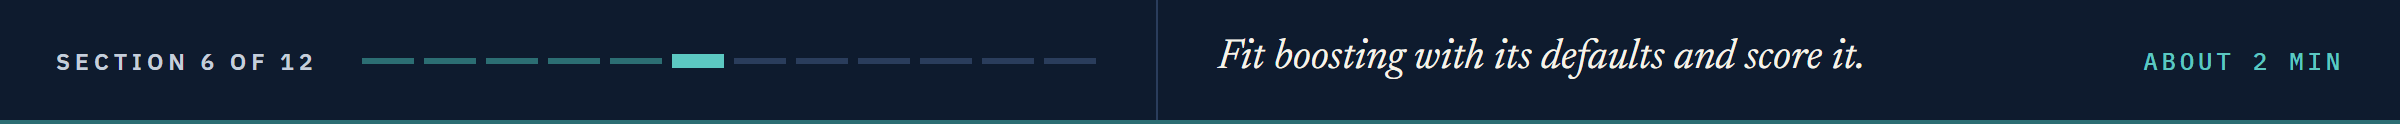

# Model Building

## Gradient Boosting With the Library's Defaults

**Gradient boosting** fits a model in **rounds**.
It starts every bond at the average log OAS, fits a small tree to what is still missed, adds a tenth of that tree's output, and repeats.
It is Day 6's boosting, small trees grown one after another, and the tenth is Day 6's learning rate.
Day 2's `.get_params()` reads its settings.

In [13]:
# gradient boosting with every setting at the library's default
gbr = GradientBoostingRegressor(random_state=SEED)
params = gbr.get_params()
print("Rounds:", params["n_estimators"], " Learning rate:", params["learning_rate"], " Depth of each tree:", params["max_depth"])

Rounds: 100  Learning rate: 0.1  Depth of each tree: 3


## Scoring It on the Same Five Folds

`cross_validate(..., return_train_score=True)` (Day 5) also scores each fold's model on the four folds it was fitted on.

In [14]:
# held-out and fitted-fold MAE in bp, five folds
scores = cross_validate(gbr, X, y, cv=folds, scoring=bp_scorer, return_train_score=True, n_jobs=1)
print("Held-out folds:", (-scores["test_score"]).round(1), " Mean:", round(-scores["test_score"].mean(), 2), "bp")
print("Fitted folds, mean:", round(-scores["train_score"].mean(), 2), "bp")

Held-out folds: [27.2 36.9 49.2 33.9 37.2]  Mean: 36.88 bp
Fitted folds, mean: 23.45 bp


### Interpretation of the Scores

Boosting misses a held-out bond by 36.88 bp, against the line's 41.72: 4.8 bp closer on bonds each fold never saw.

On the bonds it was fitted on it misses by 23.45 bp, 13 bp less: it has memorised some of them.

**Three lines beat Course 4's best line by 4.8 bp. Next we open the 100 trees.**

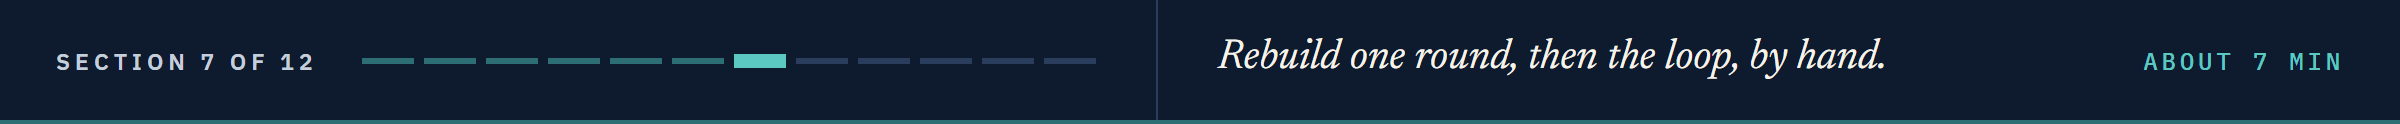

# Inside the Model, Round by Round

## Round Zero: Every Bond at the Average

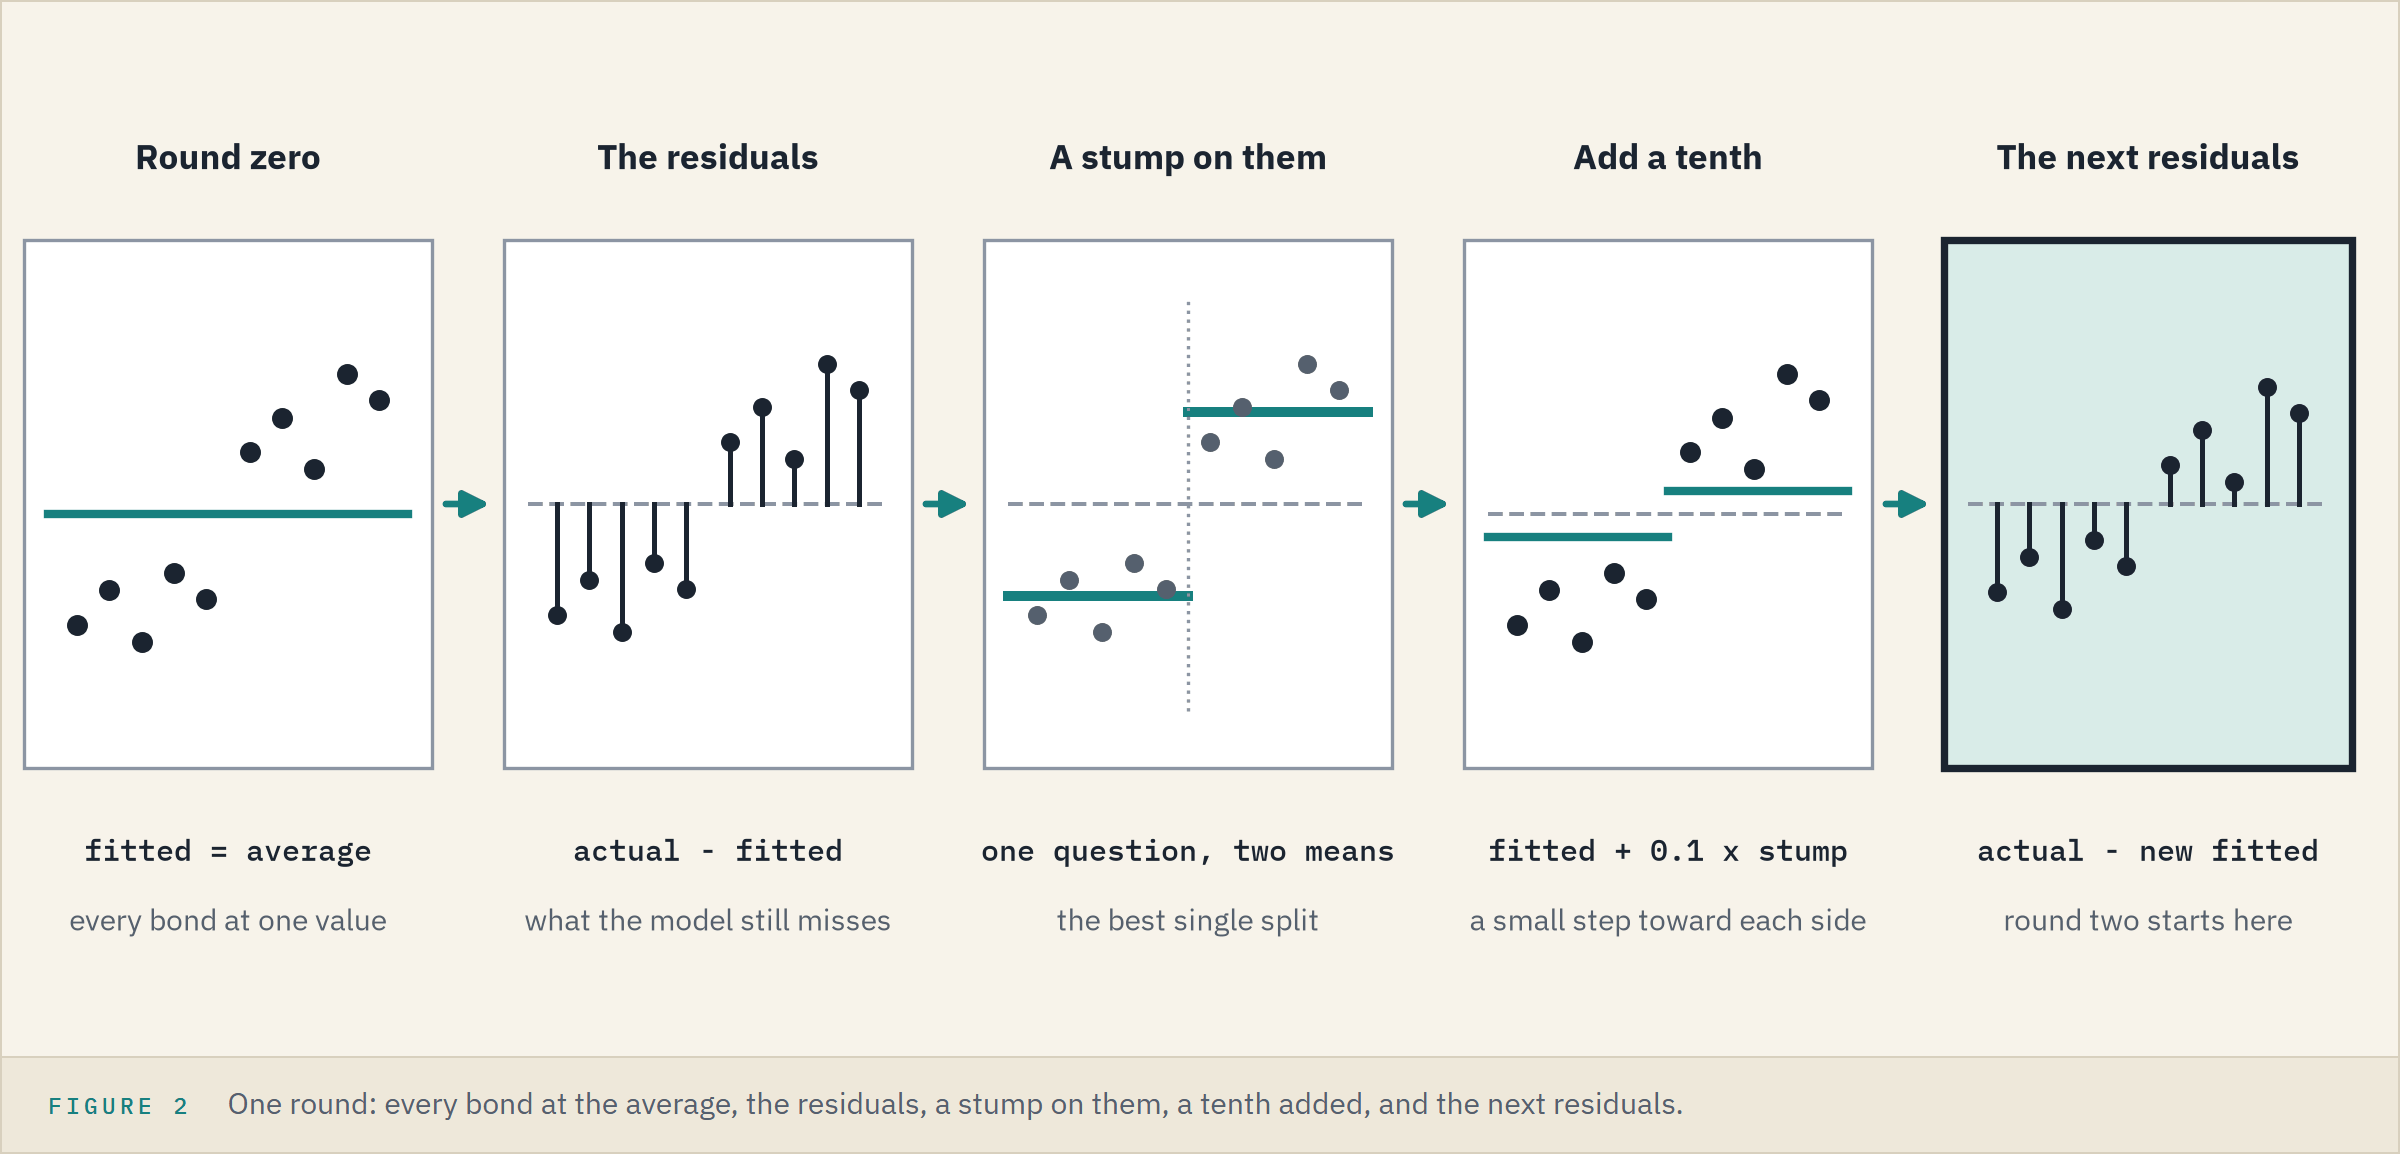

A **residual** is a bond's actual log OAS minus its fitted log OAS: what the model still misses.

In [15]:
# round zero: every bond fitted at the average log OAS, and the squared residuals that leaves
fitted0 = np.full(len(y), y.mean())
residuals0 = y - fitted0
print("Every bond at", round(np.exp(y.mean()), 1), "bp")
print("Squared residuals:", round((residuals0 ** 2).sum(), 2))

Every bond at 131.3 bp
Squared residuals: 354.13


**Predict 1**

Q. One question splits the bonds in two, and each side is fitted at its own average residual. What percent of the 354.13 squared residuals can the best single question remove? Write down a number.

## Round One: the Best Single Question

A question is a column and a threshold.
For each column we try every threshold halfway between two neighbouring values and add up the squared residuals left on the two sides.

In [16]:
# squared residuals left by every threshold of one column, each side fitted at its own mean
def split_search(column, residuals):
    values = np.sort(column.unique())
    thresholds = (values[:-1] + values[1:]) / 2
    left = [((residuals[column <= t] - residuals[column <= t].mean()) ** 2).sum() for t in thresholds]
    right = [((residuals[column > t] - residuals[column > t].mean()) ** 2).sum() for t in thresholds]
    return pd.Series(np.array(left) + np.array(right), index=thresholds)

In [17]:
# the search on three columns, and the best threshold of each
searches = {name: split_search(train[name], residuals0) for name in ["score", "years_to_maturity", "duration"]}
best = pd.DataFrame({"threshold": [s.idxmin() for s in searches.values()], "left over": [s.min() for s in searches.values()]},
                    index=list(searches))
best["percent removed"] = (1 - best["left over"] / (residuals0 ** 2).sum()) * 100
best

,threshold,left over,percent removed
score,9.500,150.457,57.514
years_to_maturity,10.995,347.264,1.940
duration,13.145,346.950,2.028


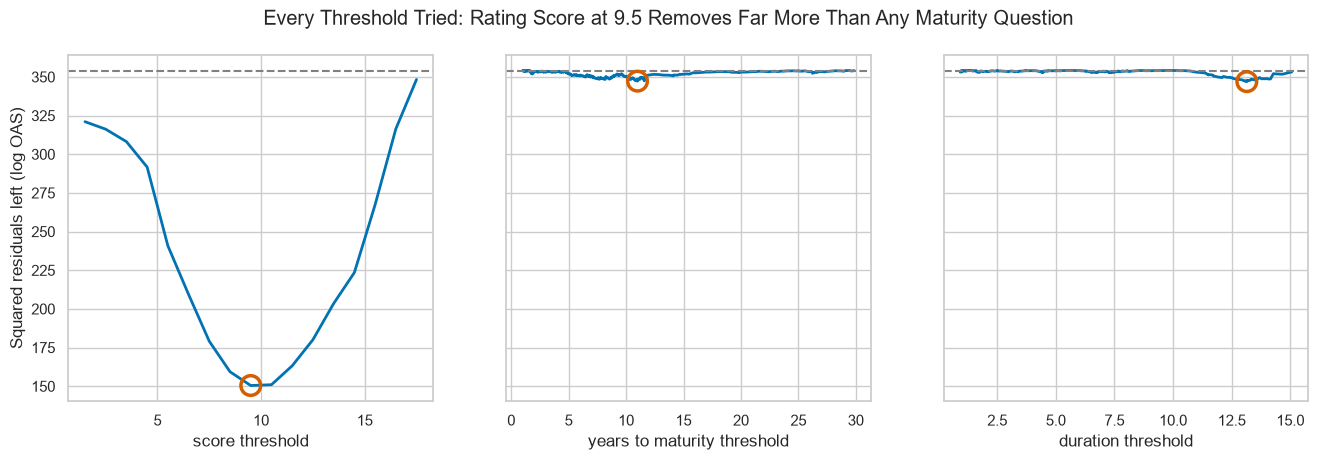

In [18]:
# the squared residuals left against every threshold, one panel per column, the best ringed, the start dashed
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (name, search) in zip(axes, searches.items()):
    ax.plot(search.index, search.values, linewidth=2)
    ax.scatter(search.idxmin(), search.min(), s=200, facecolor="none", edgecolor="C3", linewidth=2.5, zorder=3)
    ax.axhline((residuals0 ** 2).sum(), color="gray", linestyle="--")
    ax.set_xlabel(name.replace("_", " ") + " threshold")
axes[0].set_ylabel("Squared residuals left (log OAS)")
fig.suptitle("Every Threshold Tried: Rating Score at 9.5 Removes Far More Than Any Maturity Question")
plt.show()

Score at 9.5, between BBB and BBB-, leaves 150.46 of 354.13: 57.5 percent removed.

The best question on years removes 1.9 percent, on duration 2.0.

`DecisionTreeRegressor(max_depth=1)` asks the same search of every column at once: Day 6's stump, Course 4's Day 9 one-question tree.
`.tree_.value` holds each node's mean; nodes 1 and 2 are the two leaves.

In [19]:
# a stump fitted to the residuals, on all 14 columns
stump = DecisionTreeRegressor(max_depth=1, random_state=SEED).fit(X, residuals0)
print("Question:", X.columns[stump.tree_.feature[0]], "<=", stump.tree_.threshold[0])
print("Bonds on each side:", stump.tree_.n_node_samples[1], stump.tree_.n_node_samples[2])
print("Leaf means (log OAS):", stump.tree_.value[1, 0, 0].round(4), stump.tree_.value[2, 0, 0].round(4))

Question: score <= 9.5
Bonds on each side: 327 288
Leaf means (log OAS): -0.5401 0.6132


The stump finds the same question by hand: 327 bonds at BBB or better, 288 below.

Their mean residuals are -0.5401 and +0.6132 in log OAS.

## Adding a Tenth

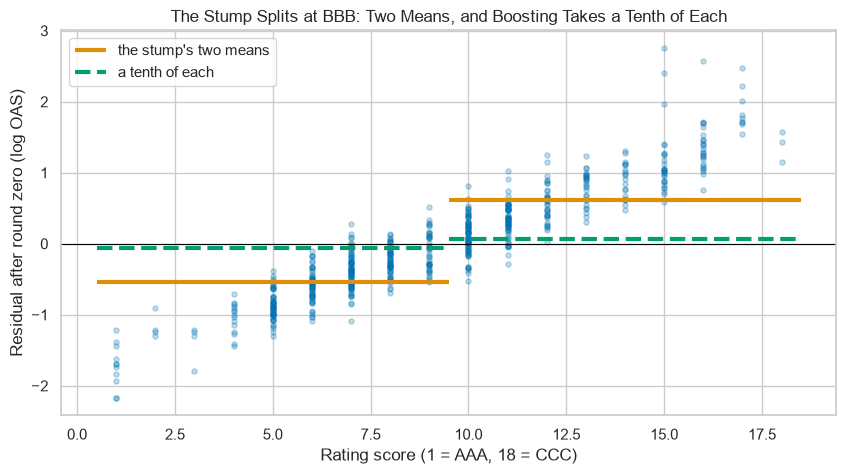

In [20]:
# the residuals against score, the stump's two means as solid steps, a tenth of each dashed
low, high = stump.tree_.value[1, 0, 0], stump.tree_.value[2, 0, 0]
plt.scatter(train["score"], residuals0, alpha=0.25, s=14)
plt.hlines([low, high], [0.5, 9.5], [9.5, 18.5], color="C1", linewidth=3, label="the stump's two means")
plt.hlines([0.1 * low, 0.1 * high], [0.5, 9.5], [9.5, 18.5], color="C2", linewidth=3, linestyle="--", label="a tenth of each")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Rating score (1 = AAA, 18 = CCC)")
plt.ylabel("Residual after round zero (log OAS)")
plt.title("The Stump Splits at BBB: Two Means, and Boosting Takes a Tenth of Each")
plt.legend()
plt.show()

In [21]:
# round one: the average plus a tenth of the stump, back in bp on each side, and in full
print("A tenth:", round(np.exp(y.mean() + 0.1 * low), 1), "and", round(np.exp(y.mean() + 0.1 * high), 1), "bp")
print("In full:", round(np.exp(y.mean() + low), 1), "and", round(np.exp(y.mean() + high), 1), "bp")

# the library with one round of one stump, against round one by hand
fitted1 = fitted0 + 0.1 * stump.predict(X)
one_round = GradientBoostingRegressor(n_estimators=1, max_depth=1, random_state=SEED).fit(X, y)
print("Largest difference:", np.abs(one_round.predict(X) - fitted1).max())

A tenth: 124.4 and 139.6 bp
In full: 76.5 and 242.4 bp
Largest difference: 0.0


Round one moves every bond from 131.3 bp to 124.4 or 139.6, a tenth of the way to the 76.5 and 242.4 the stump's means would give.

The library's one round is the same numbers exactly.

## The Loop

The default model repeats the round 100 times with trees three questions deep.

In [22]:
# start at the average; 100 times, fit a depth-3 tree to what is left and add a tenth of it
fitted = np.full(len(y), y.mean())
for round_number in range(100):
    tree = DecisionTreeRegressor(max_depth=3, random_state=SEED).fit(X, y - fitted)
    fitted = fitted + 0.1 * tree.predict(X)

# the library's default model on all 615 bonds, against the loop
gbr.fit(X, y)
print("Largest difference:", np.abs(gbr.predict(X) - fitted).max())

Largest difference: 8.881784197001252e-16


> STORY: Jerome H. Friedman's paper "Greedy function approximation: A gradient boosting machine." appeared in The Annals of Statistics, volume 29, issue 5, in October 2001; its title carries the method's name. Source: https://api.crossref.org/works/10.1214/aos/1013203451

**Gradient boosting is the mean plus a hundred small trees, each fitted to what is left, each added at a tenth.**

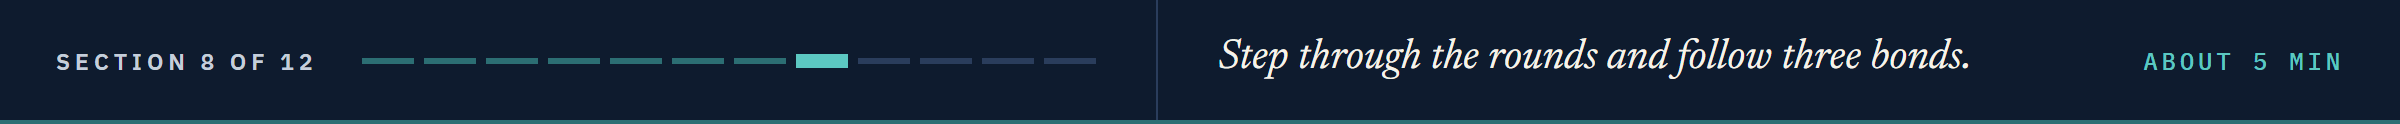

# Watching the Rounds

## Your Turn: Step Through the Rounds

To see the rounds, give boosting one column: stumps on rating score alone, 300 rounds.
`.staged_predict(rows)` hands back the fitted values after round 1, round 2, and so on; `list(...)` keeps every round.

In [23]:
# stumps on score alone, 300 rounds; every round's fit kept, for the bonds and for the 18 scores
score_model = GradientBoostingRegressor(n_estimators=300, max_depth=1, random_state=SEED).fit(train[["score"]], y)
stages = list(score_model.staged_predict(train[["score"]]))
levels = pd.DataFrame({"score": range(1, 19)})
level_fits = list(score_model.staged_predict(levels))

In [24]:
# one round: the bonds and the fit above (bp, log scale), the residuals and their spread below
def draw_round(round_number, top, bottom):
    fit = stages[round_number - 1]
    top.scatter(train["score"], train["oas"], alpha=0.15, s=12)
    top.step(levels["score"], np.exp(level_fits[round_number - 1]), where="mid", color="C3", linewidth=2.5)
    top.set_yscale("log")
    top.set_yticks([20, 50, 100, 200, 500, 1000, 2000], [20, 50, 100, 200, 500, 1000, 2000])
    top.minorticks_off()
    top.set_title(f"Round {round_number}: {len(np.unique(fit))} levels")
    bottom.scatter(train["score"], y - fit, alpha=0.15, s=12)
    bottom.axhline(0, color="black", linewidth=0.8)
    bottom.set_title(f"Residual sd {np.std(y - fit):.3f}")
    bottom.set_xlabel("Rating score")

**Predict 2**

After one round the fit has two levels, one each side of score 9.5.

Q. Sketch the fitted spread against rating score after 300 rounds.

Then drag the round, as with Course 4's Day 1 slider, and watch the fit and the residuals.

In [25]:
# your turn: drag the round from 1 to 300
def show_round(round_number=1):
    fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
    draw_round(round_number, top, bottom)
    plt.show()

interact(show_round, round_number=(1, 300));

interactive(children=(IntSlider(value=1, description='round_number', max=300, min=1), Output()), _dom_classes=…

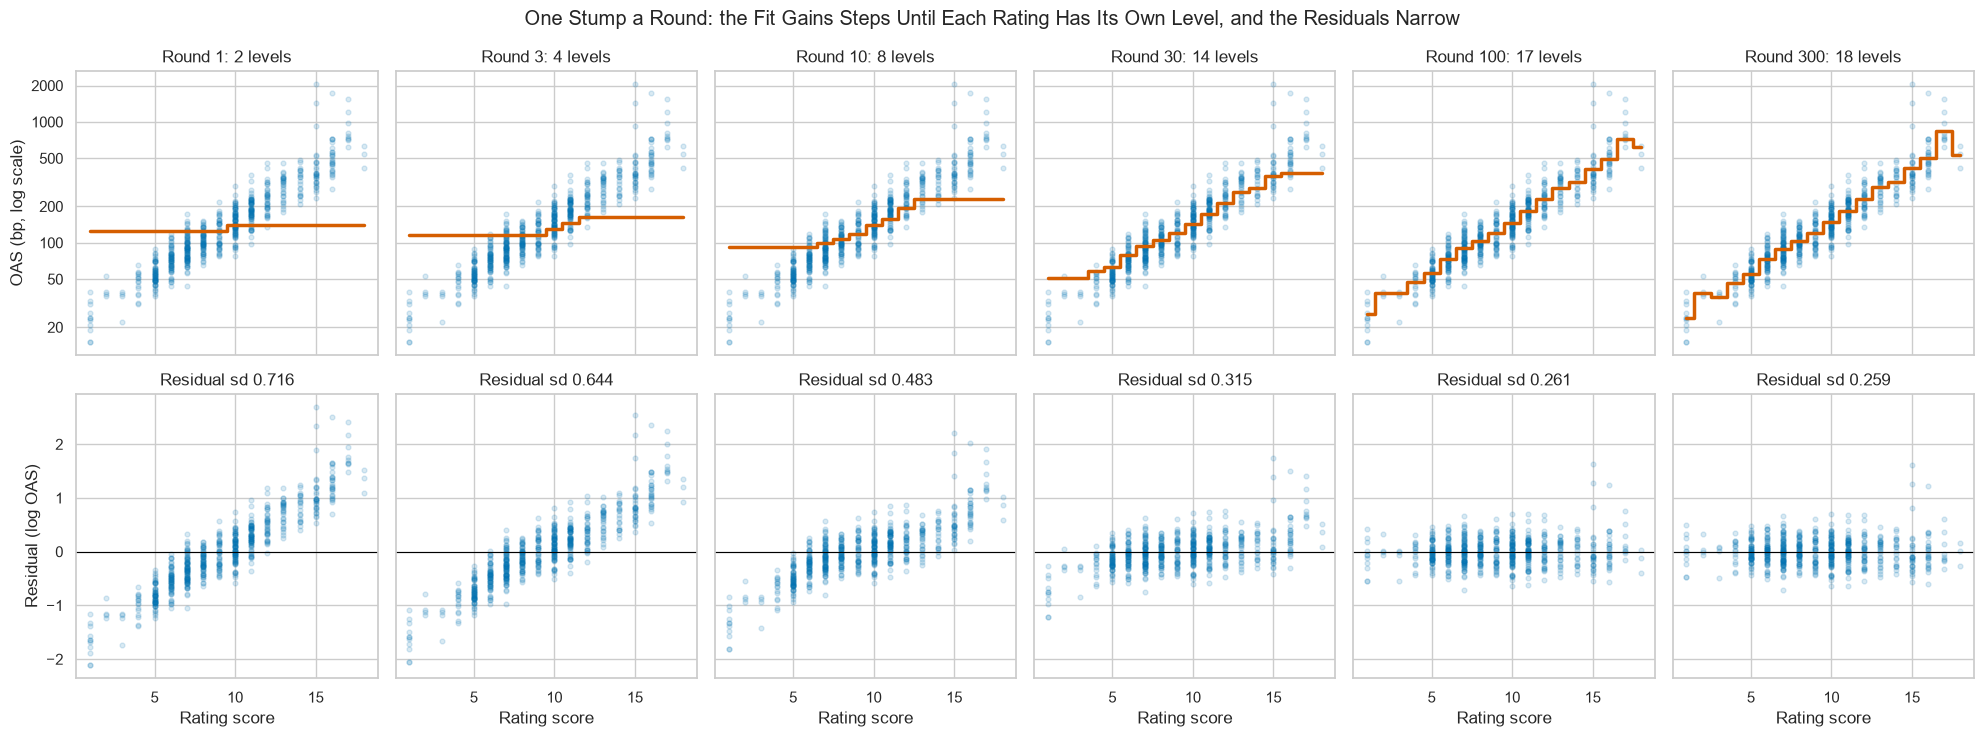

In [26]:
# the slider's starting position and five later rounds, drawn as a still picture (sliders do not run on GitHub)
fig, axes = plt.subplots(2, 6, figsize=(20, 7.5), sharex=True, sharey="row")
for column, round_number in enumerate([1, 3, 10, 30, 100, 300]):
    draw_round(round_number, axes[0, column], axes[1, column])
axes[0, 0].set_ylabel("OAS (bp, log scale)")
axes[1, 0].set_ylabel("Residual (log OAS)")
fig.suptitle("One Stump a Round: the Fit Gains Steps Until Each Rating Has Its Own Level, and the Residuals Narrow")
plt.tight_layout()
plt.show()

In [27]:
# the residuals' spread and the number of fitted levels, before any round and after six of them
rounds = [1, 3, 10, 30, 100, 300]
pd.DataFrame({"residual sd": [np.std(residuals0)] + [np.std(y - stages[k - 1]) for k in rounds],
              "fitted levels": [1] + [len(np.unique(stages[k - 1])) for k in rounds]}, index=[0] + rounds)

,residual sd,fitted levels
0,0.759,1
1,0.716,2
3,0.644,4
10,0.483,8
30,0.315,14
100,0.261,17
300,0.259,18


After one round the fit is one step; each later round splits a step again.

By round 100 nearly every score has its own level, and the residuals' spread falls from 0.759 to 0.261, then barely moves.

Score has 18 levels in these bonds, so the fit cannot hold more than 18 steps.

## Three Bonds Closing In

In [28]:
# the narrowest bond, the bond nearest the average of 131.3 bp, and the widest
three = [train["oas"].idxmin(), (train["oas"] - np.exp(y.mean())).abs().idxmin(), train["oas"].idxmax()]
train.loc[three, ["cusip", "issuer", "rating", "oas"]]

,cusip,issuer,rating,oas
158,99030EAG0,Dralane Networks,AAA,15
449,99085HAB8,Tromazor Resources,BBB-,131
386,99072UAF5,Zephane Utilities,B,2074


In [29]:
# the default model's fitted spread for each of the three, in bp, after every round
paths = pd.DataFrame(np.exp(list(gbr.staged_predict(X.loc[three]))), columns=train.loc[three, "issuer"], index=range(1, 101))
paths.loc[[1, 10, 30, 100]]

issuer,Dralane Networks,Tromazor Resources,Zephane Utilities
1,112.668,132.822,144.411
10,45.377,137.400,285.888
30,24.715,139.435,506.464
100,19.448,133.436,"1,733.064"


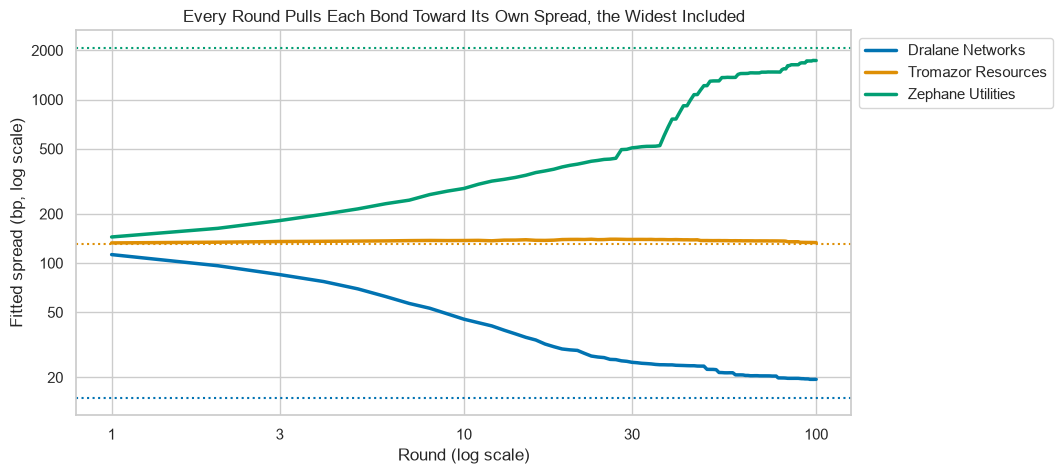

In [30]:
# the three paths over 100 rounds, each bond's own spread dotted, both axes on a log scale
for issuer, own, colour in zip(paths.columns, train.loc[three, "oas"], ["C0", "C1", "C2"]):
    plt.plot(paths.index, paths[issuer], color=colour, linewidth=2.5, label=issuer)
    plt.axhline(own, color=colour, linestyle=":")
plt.xscale("log")
plt.yscale("log")

# plain numbers on both log axes, as on Day 5's maturity chart
plt.xticks([1, 3, 10, 30, 100], [1, 3, 10, 30, 100])
plt.yticks([20, 50, 100, 200, 500, 1000, 2000], [20, 50, 100, 200, 500, 1000, 2000])
plt.minorticks_off()
plt.xlabel("Round (log scale)")
plt.ylabel("Fitted spread (bp, log scale)")
plt.title("Every Round Pulls Each Bond Toward Its Own Spread, the Widest Included")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

Dralane Networks, AAA at 15 bp, starts at 112.7 bp and reaches 19.4 by round 100.

Tromazor Resources, at 131 bp, stays within 9 bp of it all the way.

Zephane Utilities, the widest bond at 2,074 bp, climbs from 144.4 to 1,733.1 on its own row.

**Every round closes on the bonds it sees, the widest one included. That is how boosting memorises, so we watch rounds on unseen bonds.**

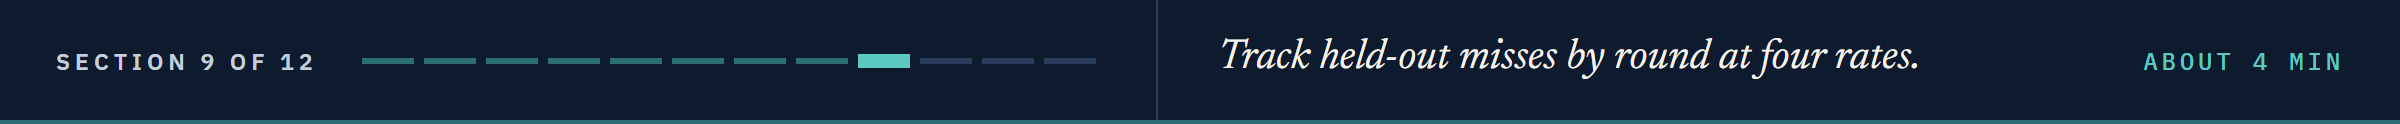

# Rounds and the Learning Rate

## Training Against Held-Out Misses by Round

Each fold's model is run to 1,000 rounds and scored after every round, on its held-out bonds and on its fitted ones.
Every fold holds 123 bonds, so the miss over all 615 held-out fitted values equals the mean of the five folds.

In [31]:
# held-out and fitted-fold MAE in bp after every one of 1,000 rounds at one learning rate, on the five folds
def round_curves(rate, rounds=1000):
    held, fitted_folds = np.zeros((rounds, len(X))), np.zeros((rounds, 5))
    for fold, (fit_rows, held_rows) in enumerate(folds.split(X)):
        model = GradientBoostingRegressor(n_estimators=rounds, learning_rate=rate, random_state=SEED).fit(X.iloc[fit_rows], y.iloc[fit_rows])
        for k, fit in enumerate(model.staged_predict(X.iloc[held_rows])):
            held[k, held_rows] = fit
        fitted_folds[:, fold] = [mae_bp(y.iloc[fit_rows], fit) for fit in model.staged_predict(X.iloc[fit_rows])]
    return pd.DataFrame({"held-out": [mae_bp(y, h) for h in held], "fitted folds": fitted_folds.mean(axis=1)},
                        index=range(1, rounds + 1))

In [32]:
# the default rate, 0.1, run to 1,000 rounds
curves = {0.1: round_curves(0.1)}
best_round = curves[0.1]["held-out"].idxmin()
print("Lowest held-out MAE:", round(curves[0.1]["held-out"].min(), 1), "bp at round", best_round)
curves[0.1].loc[[100, 1000]]

Lowest held-out MAE: 36.1 bp at round 272


,held-out,fitted folds
100,36.880,23.451
1000,37.109,2.658


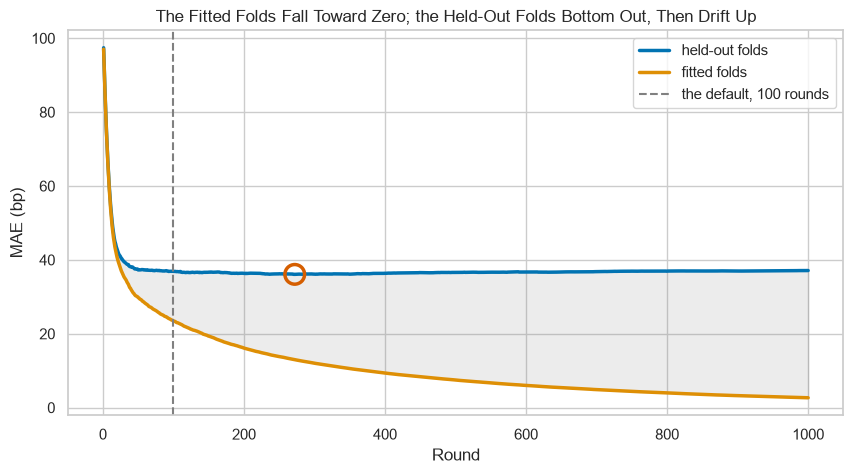

In [33]:
# both curves by round, the gap shaded, the lowest held-out point ringed, the default's 100 rounds dashed
curve = curves[0.1]
plt.plot(curve.index, curve["held-out"], linewidth=2.5, label="held-out folds")
plt.plot(curve.index, curve["fitted folds"], linewidth=2.5, label="fitted folds")
plt.fill_between(curve.index, curve["fitted folds"], curve["held-out"], alpha=0.15, color="gray")
plt.scatter(best_round, curve["held-out"].min(), s=200, facecolor="none", edgecolor="C3", linewidth=2.5, zorder=3)
plt.axvline(100, color="gray", linestyle="--", label="the default, 100 rounds")
plt.xlabel("Round")
plt.ylabel("MAE (bp)")
plt.title("The Fitted Folds Fall Toward Zero; the Held-Out Folds Bottom Out, Then Drift Up")
plt.legend()
plt.show()

The fitted-fold miss falls from 23.5 bp at round 100 to 2.7 at round 1,000: the model memorises its rows.

The held-out miss is lowest at round 272, 36.1 bp, and drifts up to 37.1 by round 1,000.

## Four Learning Rates

**Predict 3**

Q. At the default rate the held-out miss is lowest at round 272. Triple the rate to 0.3: at which round is it lowest? Write down a number.

In [34]:
# three more rates, then each rate's lowest held-out MAE, its round, and its MAE at round 1,000
for rate in [0.3, 0.05, 0.01]:
    curves[rate] = round_curves(rate)
pd.DataFrame({"lowest": [curves[r]["held-out"].min() for r in curves],
              "at round": [curves[r]["held-out"].idxmin() for r in curves],
              "at round 1,000": [curves[r]["held-out"].iloc[-1] for r in curves]}, index=list(curves)).sort_index(ascending=False)

,lowest,at round,"at round 1,000"
0.300,36.600,90,38.069
0.100,36.072,272,37.109
0.050,36.331,566,37.007
0.010,37.344,1000,37.344


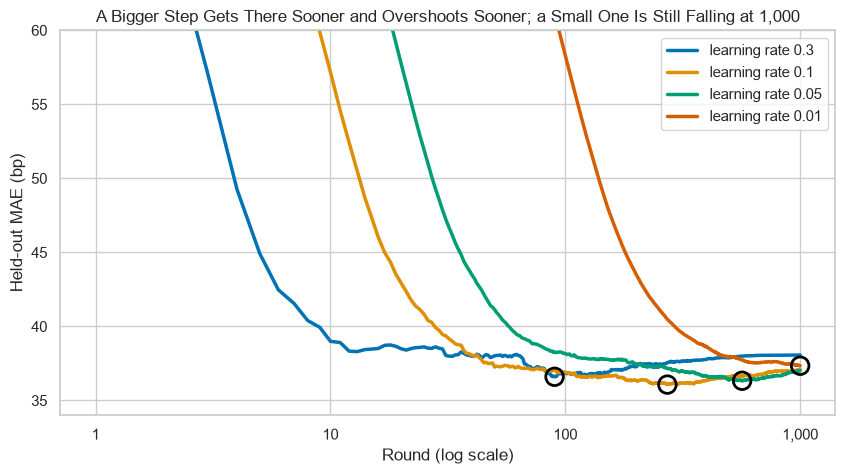

In [35]:
# the four held-out curves on a log rounds axis, each lowest point ringed
for rate in sorted(curves, reverse=True):
    held = curves[rate]["held-out"]
    plt.plot(held.index, held, linewidth=2.5, label=f"learning rate {rate}")
    plt.scatter(held.idxmin(), held.min(), s=160, facecolor="none", edgecolor="black", linewidth=2, zorder=3)
plt.xscale("log")
plt.xticks([1, 10, 100, 1000], ["1", "10", "100", "1,000"])
plt.minorticks_off()
plt.ylim(34, 60)
plt.xlabel("Round (log scale)")
plt.ylabel("Held-out MAE (bp)")
plt.title("A Bigger Step Gets There Sooner and Overshoots Sooner; a Small One Is Still Falling at 1,000")
plt.legend()
plt.show()

At 0.3 the miss bottoms at 36.6 bp by round 90 and is 38.1 by round 1,000.

At 0.05 it bottoms at 36.3 by round 566; at 0.01 it is still falling at round 1,000.

The rate trades with the rounds: big steps learn fast, then fit noise.

**These curves describe the five folds, and each lowest point flatters the setting that drew it. We keep the defaults, fixed before looking; Day 11 tunes honestly.**

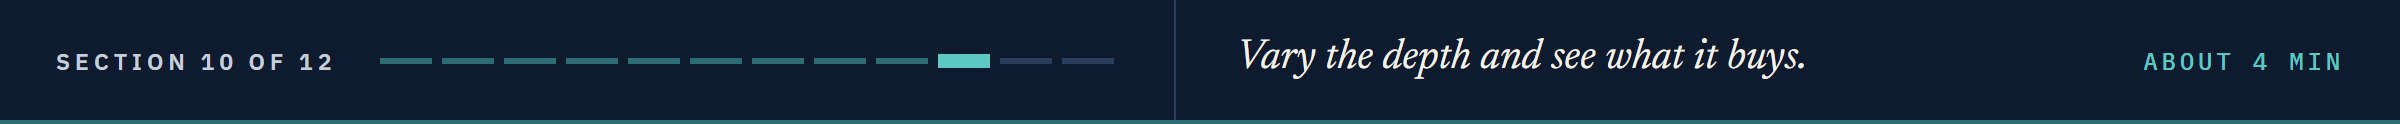

# How Deep Each Tree

## Depth on Fitted and Held-Out Bonds

In [36]:
# five-fold MAE in bp, fitted and held-out, for trees of depth 1 to 8, 100 rounds at 0.1
depths = [1, 2, 3, 4, 5, 6, 8]
depth_scores = pd.DataFrame(index=depths, columns=["fitted folds", "held-out"], dtype=float)
for depth in depths:
    result = cross_validate(GradientBoostingRegressor(max_depth=depth, random_state=SEED), X, y, cv=folds, scoring=bp_scorer,
                            return_train_score=True, n_jobs=1)
    depth_scores.loc[depth] = [-result["train_score"].mean(), -result["test_score"].mean()]
depth_scores

,fitted folds,held-out
1,38.884,40.680
2,30.982,39.552
3,23.451,36.880
4,16.549,37.045
5,10.023,37.430
6,5.191,39.105
8,0.997,44.651


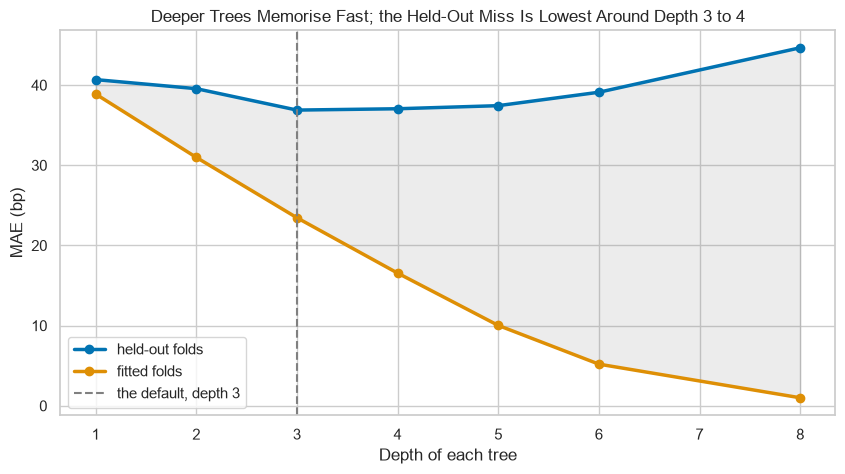

In [37]:
# the two curves against depth, the gap shaded, the default's depth 3 dashed
plt.plot(depth_scores.index, depth_scores["held-out"], marker="o", linewidth=2.5, label="held-out folds")
plt.plot(depth_scores.index, depth_scores["fitted folds"], marker="o", linewidth=2.5, label="fitted folds")
plt.fill_between(depth_scores.index, depth_scores["fitted folds"], depth_scores["held-out"], alpha=0.15, color="gray")
plt.axvline(3, color="gray", linestyle="--", label="the default, depth 3")
plt.xlabel("Depth of each tree")
plt.ylabel("MAE (bp)")
plt.title("Deeper Trees Memorise Fast; the Held-Out Miss Is Lowest Around Depth 3 to 4")
plt.legend()
plt.show()

Stumps miss held-out bonds by 40.68 bp, depth 3 by 36.88, depth 8 by 44.65.

The fitted-fold miss falls from 38.88 to 1.00: depth 8 memorises.

## What Depth Buys: Two Columns at Once

Day 6 called a sum of stumps an additive model: every stump reads one column, so the fit adds one column's steps to another's.
A depth-3 tree can ask about years and then about duration, so its step in duration can differ by maturity: an **interaction**.

In [38]:
# five-fold MAE in bp of one model on some of the columns
def cv_bp(model, columns):
    return -cross_val_score(model, X[columns], y, cv=folds, scoring=bp_scorer, n_jobs=1).mean()

# least squares, stumps and depth-3 trees, on two sets of columns
sets = {"score and years": ["score", "years_to_maturity"], "score, years and duration": ["score", "years_to_maturity", "duration"]}
pd.DataFrame({name: [cv_bp(LinearRegression(), cols), cv_bp(GradientBoostingRegressor(max_depth=1, random_state=SEED), cols),
                     cv_bp(GradientBoostingRegressor(random_state=SEED), cols)] for name, cols in sets.items()},
             index=["least squares", "stumps", "depth 3"]).T

,least squares,stumps,depth 3
score and years,42.315,40.512,41.242
"score, years and duration",42.329,40.652,36.418


In [39]:
# stumps and depth-3 trees on score, years and duration, fitted on all 615 bonds
three_columns = ["score", "years_to_maturity", "duration"]
stumps3 = GradientBoostingRegressor(max_depth=1, random_state=SEED).fit(X[three_columns], y)
depth3 = GradientBoostingRegressor(random_state=SEED).fit(X[three_columns], y)

# cells of 1 year by half a year of duration; np.histogram2d counts the training bonds in each cell
year_edges, duration_edges = np.arange(0, 31.0), np.arange(0.5, 16.0, 0.5)
counts = np.histogram2d(train["duration"], train["years_to_maturity"], bins=[duration_edges, year_edges])[0]
years_grid, duration_grid = np.meshgrid(year_edges[:-1] + 0.5, duration_edges[:-1] + 0.25)
grid = pd.DataFrame({"score": 9, "years_to_maturity": years_grid.ravel(), "duration": duration_grid.ravel()})

# each model's fitted spread in bp at score 9 (BBB) in the middle of every cell, blank where no training bond sits
surfaces = {}
for name, model in [("Stumps", stumps3), ("Depth 3", depth3)]:
    surfaces[name] = np.exp(model.predict(grid)).reshape(years_grid.shape)
    surfaces[name][counts == 0] = np.nan

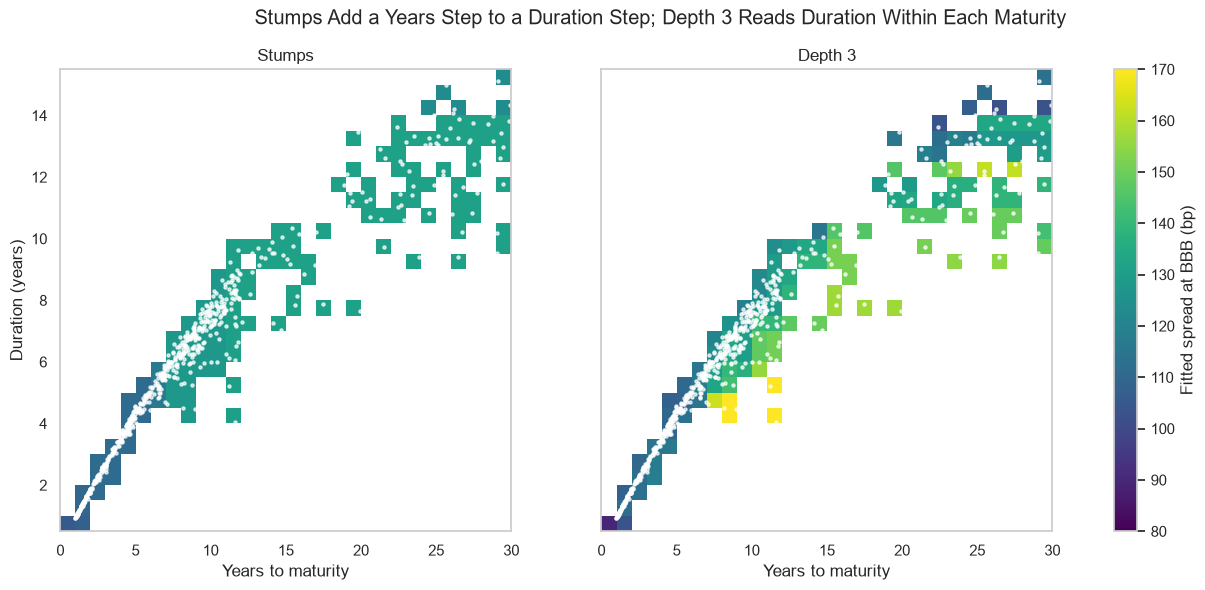

In [40]:
# the two fitted surfaces side by side on one colour scale, the training bonds dotted
# origin="lower" puts the first row of cells at the bottom; extent= gives the axes their years and durations
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, (name, surface) in zip(axes, surfaces.items()):
    image = ax.imshow(surface, origin="lower", aspect="auto", extent=[0, 30, 0.5, 15.5], cmap="viridis", vmin=80, vmax=170)
    ax.scatter(train["years_to_maturity"], train["duration"], s=5, color="white", alpha=0.7)
    ax.grid(False)
    ax.set_title(name)
    ax.set_xlabel("Years to maturity")
axes[0].set_ylabel("Duration (years)")
fig.colorbar(image, ax=axes, label="Fitted spread at BBB (bp)")
fig.suptitle("Stumps Add a Years Step to a Duration Step; Depth 3 Reads Duration Within Each Maturity")
plt.show()

### Interpretation of the Interaction

In [41]:
# each model's fitted spread in bp at score 9 and 10 years, at two durations
points = pd.DataFrame({"score": 9, "years_to_maturity": 10, "duration": [7.0, 7.8]})
pd.DataFrame({"stumps": np.exp(stumps3.predict(points)), "depth 3": np.exp(depth3.predict(points))}, index=["duration 7.0", "duration 7.8"])

,stumps,depth 3
duration 7.0,128.070,140.017
duration 7.8,128.070,126.769


On score and years alone depth buys nothing; add duration and depth 3 drops to 36.42 bp, while stumps and the line stay near 41 and 42.

At 10 years the depth-3 model fits 140.0 bp at duration 7.0 and 126.8 at 7.8.

The course's generator sets each yield as the Treasury yield plus the spread, then computes duration from coupon and yield, so at one maturity a shorter duration goes with a higher yield and a wider spread.

**Depth lets a tree read years and duration together, where this file hides part of the spread. Stumps cannot.**

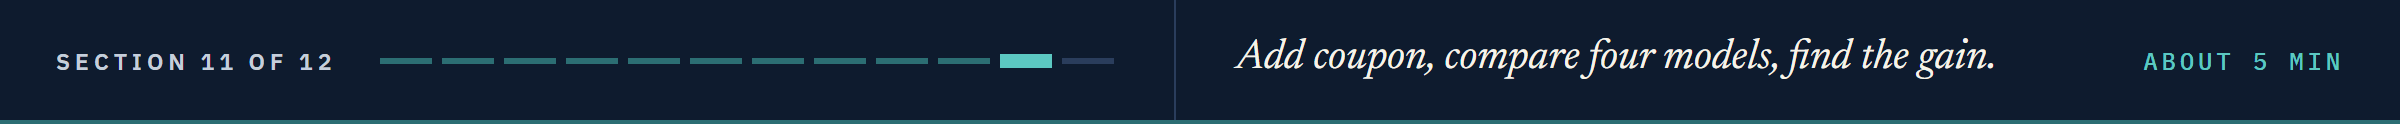

# Model Performance Comparison

## Least Squares and Boosting, Without and With Coupon

`HistGradientBoostingRegressor` is scikit-learn's fast version of the same model, built for large files.
Day 5's tuned forest, `max_features=0.75`, joins as week 1's best on these bonds.

**Predict 4**

Q. Least squares with coupon misses by 37.19 bp; boosting without coupon by 36.88. Write down boosting's miss with coupon.

In [42]:
# each model's MAE in bp on the five held-out folds, without and with coupon
with_coupon = X.assign(coupon=train["coupon"])
fold_mae = {}
for label, tree_X, numbers in [("without coupon", X, NO_COUPON), ("with coupon", with_coupon, NO_COUPON + ["coupon"])]:
    fold_mae[("least squares", label)] = -cross_val_score(make_line(numbers), train, y, cv=folds, scoring=bp_scorer, n_jobs=1)
    fold_mae[("boosting", label)] = -cross_val_score(GradientBoostingRegressor(random_state=SEED), tree_X, y, cv=folds, scoring=bp_scorer, n_jobs=1)
    fold_mae[("Hist boosting", label)] = -cross_val_score(HistGradientBoostingRegressor(random_state=SEED), tree_X, y, cv=folds, scoring=bp_scorer, n_jobs=1)
    fold_mae[("Day 5's forest", label)] = -cross_val_score(RandomForestRegressor(max_features=0.75, random_state=SEED, n_jobs=1), tree_X, y,
                                                           cv=folds, scoring=bp_scorer, n_jobs=1)
fold_mae = pd.DataFrame(fold_mae, index=[1, 2, 3, 4, 5])
fold_mae.T.assign(mean=fold_mae.mean())

,,1,2,3,4,5,mean
least squares,without coupon,30.091,36.166,61.782,39.299,41.244,41.717
boosting,without coupon,27.152,36.917,49.249,33.919,37.161,36.880
Hist boosting,without coupon,32.003,39.003,59.577,31.663,39.336,40.316
Day 5's forest,without coupon,29.958,32.620,60.756,31.373,40.380,39.017
least squares,with coupon,28.789,34.933,55.971,31.713,34.532,37.188
boosting,with coupon,29.368,37.687,58.555,30.201,30.807,37.324
Hist boosting,with coupon,31.232,38.705,54.693,31.795,34.870,38.259
Day 5's forest,with coupon,28.668,37.473,55.797,30.037,35.694,37.534


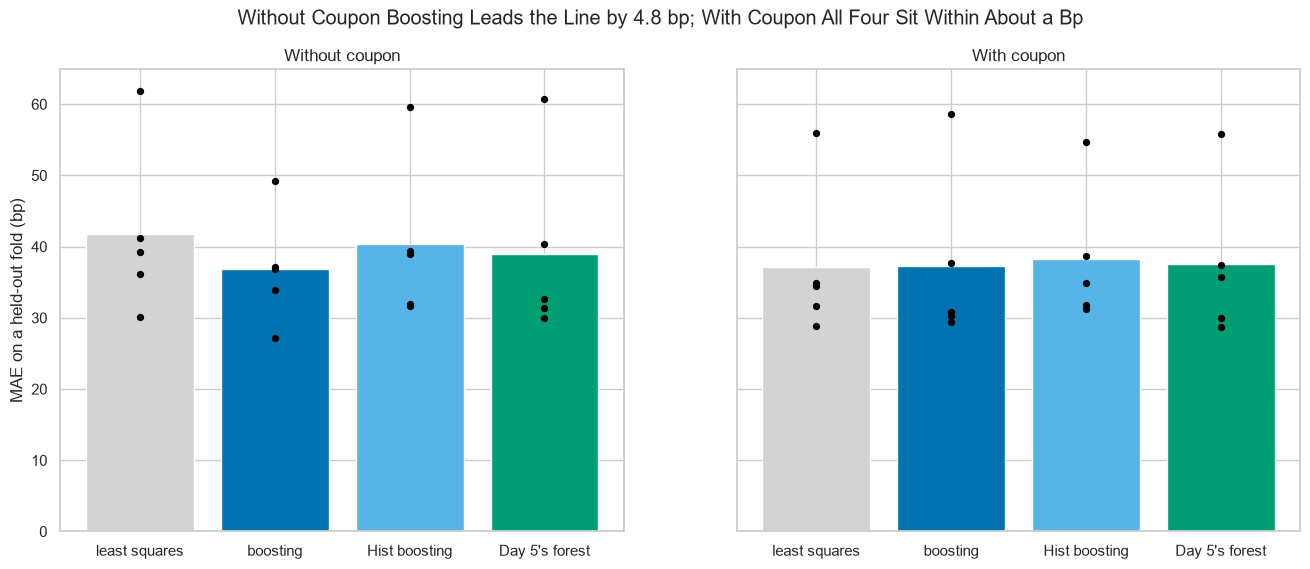

In [43]:
# mean MAE per model as a bar, each fold as a dot: without coupon on the left, with coupon on the right
models = ["least squares", "boosting", "Hist boosting", "Day 5's forest"]
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, label in zip(axes, ["without coupon", "with coupon"]):
    # .xs(label, axis=1, level=1) keeps the columns whose second name is that label
    table = fold_mae.xs(label, axis=1, level=1)[models]
    ax.bar(models, table.mean(), color=["lightgray", "C0", "C9", "C2"])
    for name in models:
        ax.scatter([name] * 5, table[name], color="black", s=18, zorder=3)
    ax.set_title(label.capitalize())
axes[0].set_ylabel("MAE on a held-out fold (bp)")
fig.suptitle("Without Coupon Boosting Leads the Line by 4.8 bp; With Coupon All Four Sit Within About a Bp")
plt.show()

Without coupon boosting leads at 36.88 bp, closer than the line in 4 of 5 folds; with coupon the line, 37.19, edges boosting, 37.32.

The fold-to-fold spread, about 10 bp, dwarfs every gap with coupon.

The fast version gives 40.32 and 38.26: it sorts each column into at most 255 bins and wants at least 20 bonds in a leaf by default, settings made for files far larger than 615 rows.

## Where the Gain Comes From

Course 4's Day 4 drew the course's recipe for a spread, with a maturity factor in it.
The generator writes that factor as `0.70 + 0.30 * min(years, 10) / 10`, so it rises to 10 years and then stays flat.
On score and years alone, stumps miss by 40.51 bp and the line by 42.31.

In [44]:
# along years at score 9: the recipe's term, the line's slope and the stumps' steps, in log OAS, each from 0 at half a year
# np.minimum takes the smaller of each pair, so years past 10 count as 10
two_columns = ["score", "years_to_maturity"]
line_two = LinearRegression().fit(X[two_columns], y)
stumps_two = GradientBoostingRegressor(max_depth=1, random_state=SEED).fit(X[two_columns], y)
years_line = np.arange(0.5, 30.01, 0.5)
along = pd.DataFrame({"score": 9, "years_to_maturity": years_line})
shapes = pd.DataFrame({"the recipe": np.log(0.70 + 0.30 * np.minimum(years_line, 10) / 10), "least squares": line_two.predict(along),
                       "stumps": stumps_two.predict(along)}, index=years_line)
shapes = shapes - shapes.iloc[0]
shapes.loc[[10.0, 20.0, 30.0]]

,the recipe,least squares,stumps
10.000,0.335,0.091,0.209
20.000,0.335,0.187,0.235
30.000,0.335,0.284,0.235


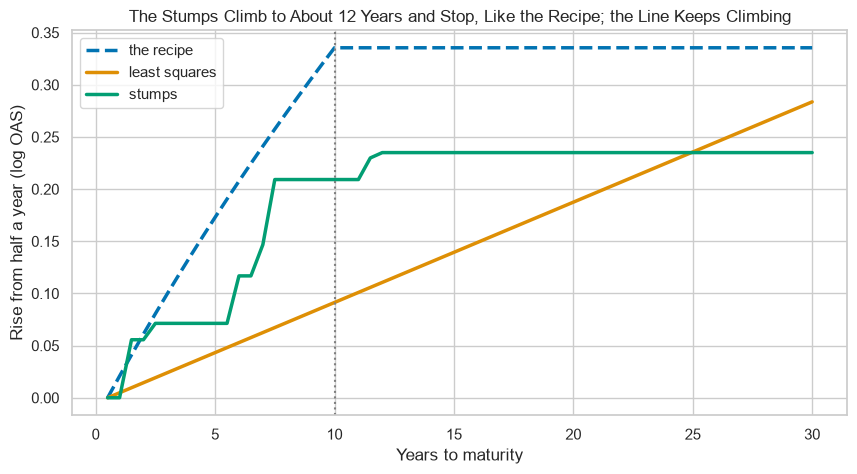

In [45]:
# the three shapes against years, the recipe's cap at 10 years dashed
for name, style in [("the recipe", "--"), ("least squares", "-"), ("stumps", "-")]:
    plt.plot(shapes.index, shapes[name], linestyle=style, linewidth=2.5, label=name)
plt.axvline(10, color="gray", linestyle=":")
plt.xlabel("Years to maturity")
plt.ylabel("Rise from half a year (log OAS)")
plt.title("The Stumps Climb to About 12 Years and Stop, Like the Recipe; the Line Keeps Climbing")
plt.legend()
plt.show()

The recipe rises 0.335 by 10 years and stays there; the stumps rise 0.209 and then sit between 0.209 and 0.235.

The line rises 0.091 by 10 years and 0.284 by 30: one slope must split the difference.

## Where Boosting Still Misses

In [46]:
# boosting's out-of-fold fitted log OAS without coupon, and each bond's miss in bp for boosting and the line
boost_fitted = cross_val_predict(GradientBoostingRegressor(random_state=SEED), X, y, cv=folds, n_jobs=1)
misses = train[["cusip", "issuer", "rating", "grade", "oas"]].assign(boosting=np.abs(train["oas"] - np.exp(boost_fitted)),
                                                                       line=np.abs(train["oas"] - np.exp(line_fitted)))
print(misses.groupby("grade")[["boosting", "line"]].mean())
misses.nlargest(3, "boosting")

                  boosting   line
grade                            
High Yield          72.092 85.886
Investment Grade    18.489 18.648


,cusip,issuer,rating,grade,oas,boosting,line
386,99072UAF5,Zephane Utilities,B,High Yield,2074,"1,001.393","1,700.947"
365,99069RAC4,Feskovar Devices,CCC+,High Yield,1551,999.987,828.518
47,99009JAA9,Calderby Retail,B,High Yield,1446,821.110,"1,043.286"


In [47]:
# what the default model leans on: impurity importance, largest four
pd.Series(gbr.feature_importances_, index=X.columns).nlargest(4)

score               0.929
duration            0.031
years_to_maturity   0.027
Telecom             0.003
dtype: float64

High yield bonds carry the misses: 72.1 bp for boosting against 18.5 for investment grade, and nearly all the gain on the line (85.9 and 18.6) is in high yield.

The widest bond, Zephane Utilities at 2,074 bp, is missed by 1,001.4 bp, against the line's 1,700.9.

The model leans on score, 0.93 of the impurity importance: an association in this file, never a driver.

**Without coupon boosting finds the bend at 10 years and reads duration within each maturity; give the line coupon, which carries part of the spread, and the line catches up.**

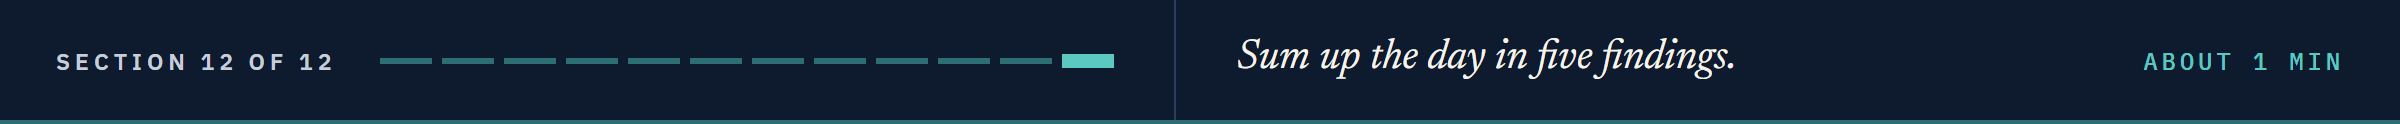

# Insights and Conclusion

With its defaults, boosting misses a held-out bond by 4.8 bp less than Course 4's line without coupon and 0.1 bp more with it.

One round is a split search and a mean; the library is the loop, to the last digit.

Rounds and the learning rate trade; depth 3 suits these bonds and depth 8 memorises them.

The gain comes with the bend at 10 years and the read of years with duration, nearly all of it in high yield.

No fitted spread here is a view on a bond.

**Day 8 runs the same rounds on log-odds for the card file, with XGBoost's penalties and early stopping. `GradientBoostingClassifier` is scikit-learn's version of that.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Fit `GradientBoostingRegressor` and score it on folds in bp, held-out and fitted.
* Run a split search by hand and match a stump's question with `.tree_`.
* Rebuild gradient boosting as a loop over residuals and match the library.
* Follow a model round by round with `.staged_predict`.
* Read rounds, learning rate and depth from held-out curves, and name an interaction.

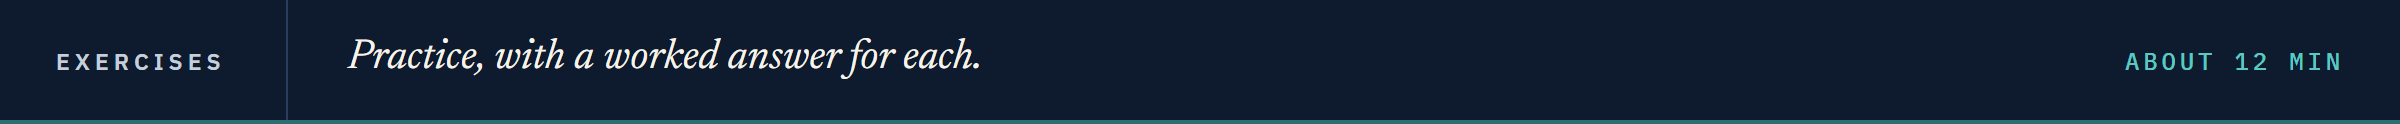

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [48]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Boosting on Spreads in bp**

Q. Fit the default model on `oas` in bp instead of its log, with `cross_val_predict` on the same folds and columns. Store the MAE in bp in `ex1_mae`.

In [49]:
# your code here
ex1_mae = ...

In [50]:
check("Exercise 1 boosting on OAS in bp", ex1_mae, 36.83681062943059)

Exercise 1 boosting on OAS in bp: not attempted yet


### Exercise 2

**Five Hundred Stumps**

Q. Score 500 stumps at learning rate 0.1 on the same folds and columns. Store the mean held-out MAE in bp in `ex2_mae`.

In [51]:
# your code here
ex2_mae = ...

In [52]:
check("Exercise 2 500 stumps", ex2_mae, 39.80118677990498)

Exercise 2 500 stumps: not attempted yet


### Exercise 3

**The Residual Path**

Q. Write `residual_path(rows, target, rounds)` that boosts stumps at rate 0.1 by hand and returns the training MAE in log OAS after each round. Check it against `.staged_predict` on score and years, and store the last of 100 rounds in `ex3_last`.

In [53]:
# your code here
ex3_last = ...

In [54]:
check("Exercise 3 the last of 100 rounds", ex3_last, 0.18604453547038213)

Exercise 3 the last of 100 rounds: not attempted yet


### Exercise 4: AI check

**The Loop That Forgot the Residuals**

You asked an AI assistant for gradient boosting by hand.
This came back.
It runs and returns 615 fitted values.
Test it, then find the bug.

In [55]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def boost_by_hand(rows, target, rounds=100, rate=0.1, depth=3):
    # start every row at the average, then add a fraction of a tree each round
    fitted = np.full(len(target), target.mean())
    for round_number in range(rounds):
        tree = DecisionTreeRegressor(max_depth=depth, random_state=SEED).fit(rows, target)
        fitted = fitted + rate * (tree.predict(rows) - fitted)
    return fitted

ai_fitted = boost_by_hand(X, y)
print(len(ai_fitted), "fitted values,", len(np.unique(ai_fitted)), "distinct; training MAE", round(mae_bp(y, ai_fitted), 2), "bp")

615 fitted values, 8 distinct; training MAE 44.73 bp


In [56]:
# the test: boosting by hand must give the library's fitted values
assert np.abs(ai_fitted - gbr.predict(X)).max() < 1e-12, "not the library's fitted values"

AssertionError: not the library's fitted values

Q. Fix the function, and store the fixed model's training MAE in bp in `ex4_mae`.

In [57]:
# your code here
ex4_mae = ...

In [58]:
check("Exercise 4 the fixed training MAE", ex4_mae, 24.6875835751551)

Exercise 4 the fixed training MAE: not attempted yet


## Congratulations!

You rebuilt gradient boosting from nothing but an average and a split search.
You matched scikit-learn to the last digit, watched a fit grow a step at a time, and saw why the rounds must be judged on bonds the model never saw.
You found the bend at 10 years that a straight line cannot make, and the place where coupon makes it beside the point.
In Day 8 the same rounds run on the card file with XGBoost, its penalties and a stop that picks itself.

[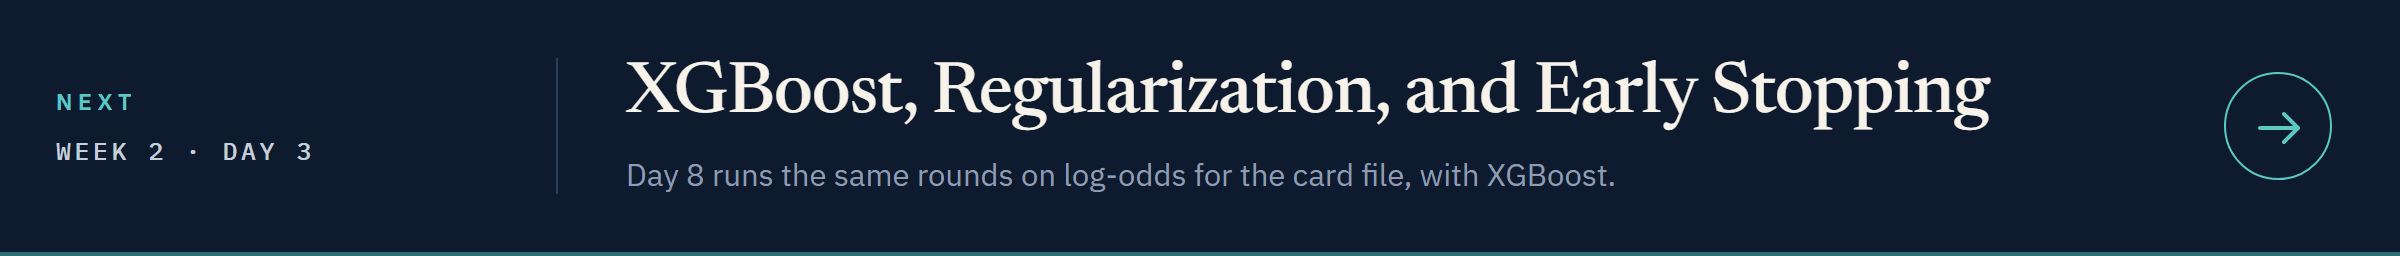](../day3/08_xgboost_regularization_and_early_stopping.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week2/day3/08_xgboost_regularization_and_early_stopping.ipynb)